In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, LSTM, GRU
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


2025-07-03 19:48:19.320994: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 19:48:19.321043: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [6]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [7]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [8]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [9]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [10]:
# Load precomputed selected features
feature_list_path = "selected_features_6class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [11]:
# Split the data into train (80%) and test (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

# Split the training data further into train (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [12]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1361814, 50)
X_val shape: (194545, 50)
X_test shape: (389090, 50)


In [13]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [14]:
def cnn_lstm_gru_model(input_shape, num_classes):

    model = Sequential([
        Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),

        Conv1D(filters=64, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),

        LSTM(64, return_sequences=True),
        GRU(64, return_sequences=False),

        Flatten(),

        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

2025-07-03 19:49:07.979019: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-07-03 19:49:07.982715: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 19:49:07.983028: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-07-03 19:49:07.983261: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-07-03 19:49:07.983453: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 48, 32)            128       
                                                                 
 max_pooling1d (MaxPooling1D  (None, 24, 32)           0         
 )                                                               
                                                                 
 conv1d_1 (Conv1D)           (None, 22, 64)            6208      
                                                                 
 max_pooling1d_1 (MaxPooling  (None, 11, 64)           0         
 1D)                                                             
                                                                 
 lstm (LSTM)                 (None, 11, 64)            33024     
                                                                 
 gru (GRU)                   (None, 64)                2

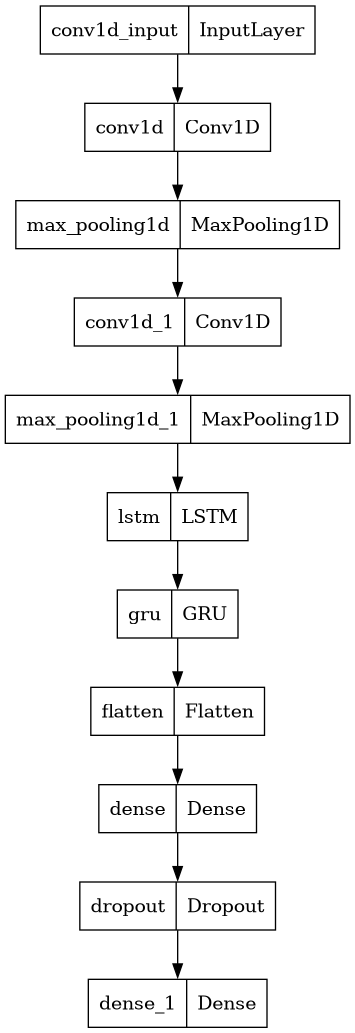

In [15]:
input_shape = (X_train.shape[1], 1)
num_classes = 6
model = cnn_lstm_gru_model(input_shape, num_classes)
model.summary()
plot_model(model)

In [16]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("CNN-LSTM-GRU_6" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [17]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,
                    batch_size=32,
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/5
42556/42557 [============================>.] - ETA: 0s - loss: 0.0961 - accuracy: 0.9559
Epoch 00001: val_accuracy improved from -inf to 0.96182, saving model to CNN-LSTM-GRU_6.h5
42557/42557 [==============================] - 1457s 34ms/step - loss: 0.0961 - accuracy: 0.9559 - val_loss: 0.0841 - val_accuracy: 0.9618
Epoch 2/5
42556/42557 [============================>.] - ETA: 0s - loss: 0.0648 - accuracy: 0.9697
Epoch 00002: val_accuracy improved from 0.96182 to 0.97382, saving model to CNN-LSTM-GRU_6.h5
42557/42557 [==============================] - 1433s 34ms/step - loss: 0.0648 - accuracy: 0.9697 - val_loss: 0.0556 - val_accuracy: 0.9738
Epoch 3/5
42556/42557 [============================>.] - ETA: 0s - loss: 0.0596 - accuracy: 0.9724
Epoch 00003: val_accuracy improved from 0.97382 to 0.97483, saving model to CNN-LSTM-GRU_6.h5
42557/42557 [==============================] - 1272s 30ms/step - loss: 0.0596 - accuracy: 0.9724 - val_loss: 0.0531 - val_accuracy: 0.9748
Epoch 4

In [18]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.133014 seconds


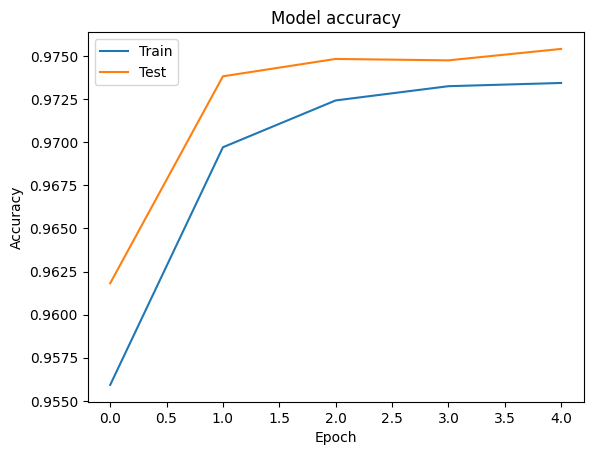

In [19]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

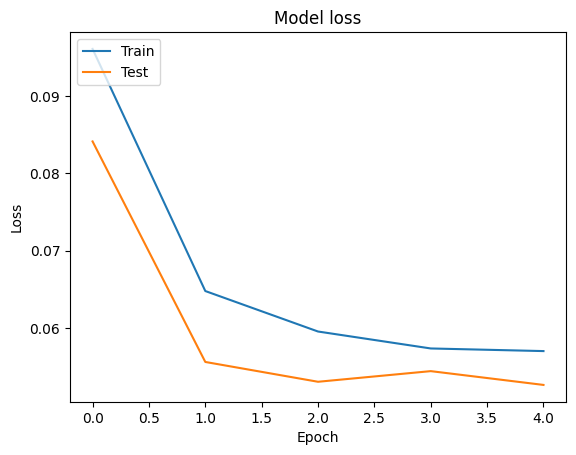

In [20]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [21]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [22]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    280115
        DDoS       0.99      0.97      0.98     57299
    Scanning       0.93      0.95      0.94     14141
   Injection       0.73      0.97      0.83     20702
        MITM       1.00      1.00      1.00        69
     Malware       0.97      0.63      0.76     16764

    accuracy                           0.98    389090
   macro avg       0.93      0.92      0.92    389090
weighted avg       0.98      0.98      0.97    389090



In [23]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

              precision  recall  f1-score      support
Normal           1.0000  1.0000    1.0000  280115.0000
DDoS             0.9881  0.9655    0.9767   57299.0000
Scanning         0.9270  0.9455    0.9362   14141.0000
Injection        0.7253  0.9655    0.8283   20702.0000
MITM             1.0000  1.0000    1.0000      69.0000
Malware          0.9656  0.6300    0.7625   16764.0000
accuracy         0.9752  0.9752    0.9752       0.9752
macro avg        0.9343  0.9178    0.9173  389090.0000
weighted avg     0.9795  0.9752    0.9749  389090.0000


In [24]:
# Binarize the true labels for multi-class AUC
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))  # shape: (n_samples, n_classes)

# y_pred is already the softmax output: shape (n_samples, n_classes)
auc_macro = roc_auc_score(y_test_bin, y_pred, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9977
AUC (weighted-averaged OvR): 0.9993


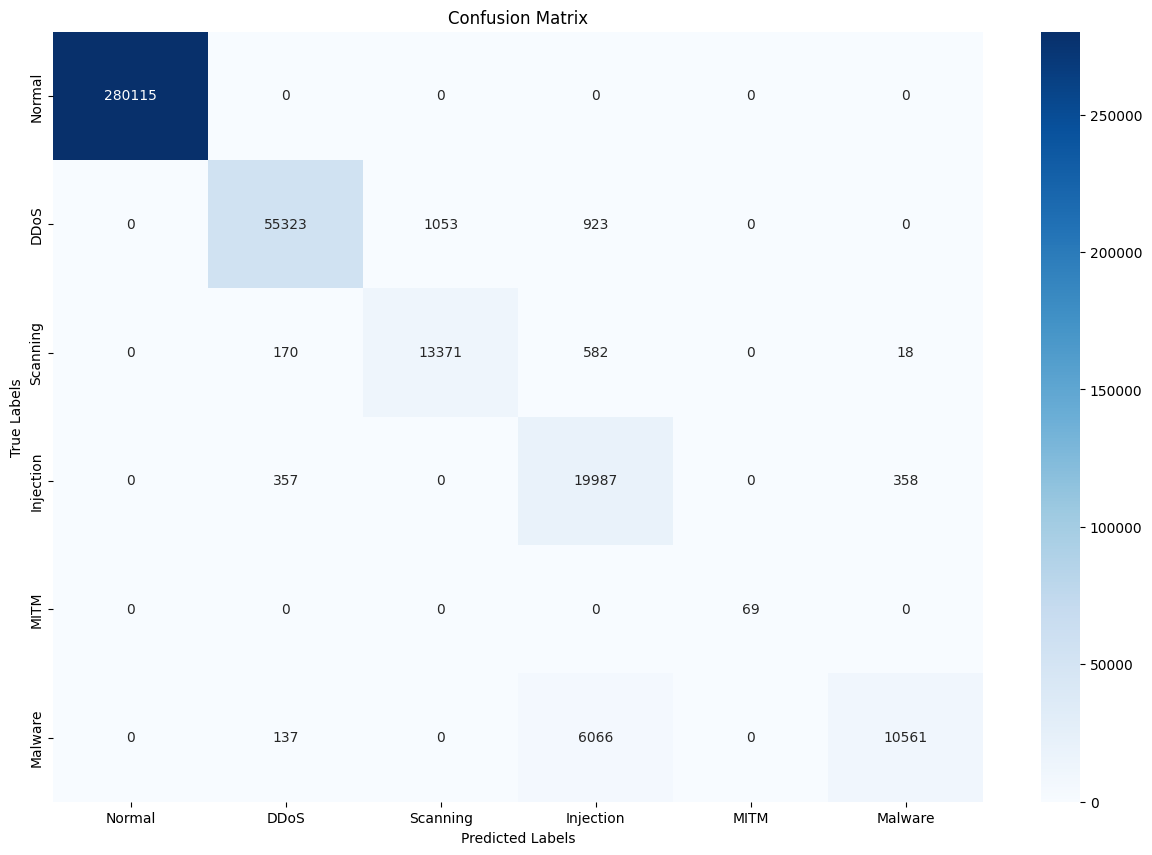

In [25]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

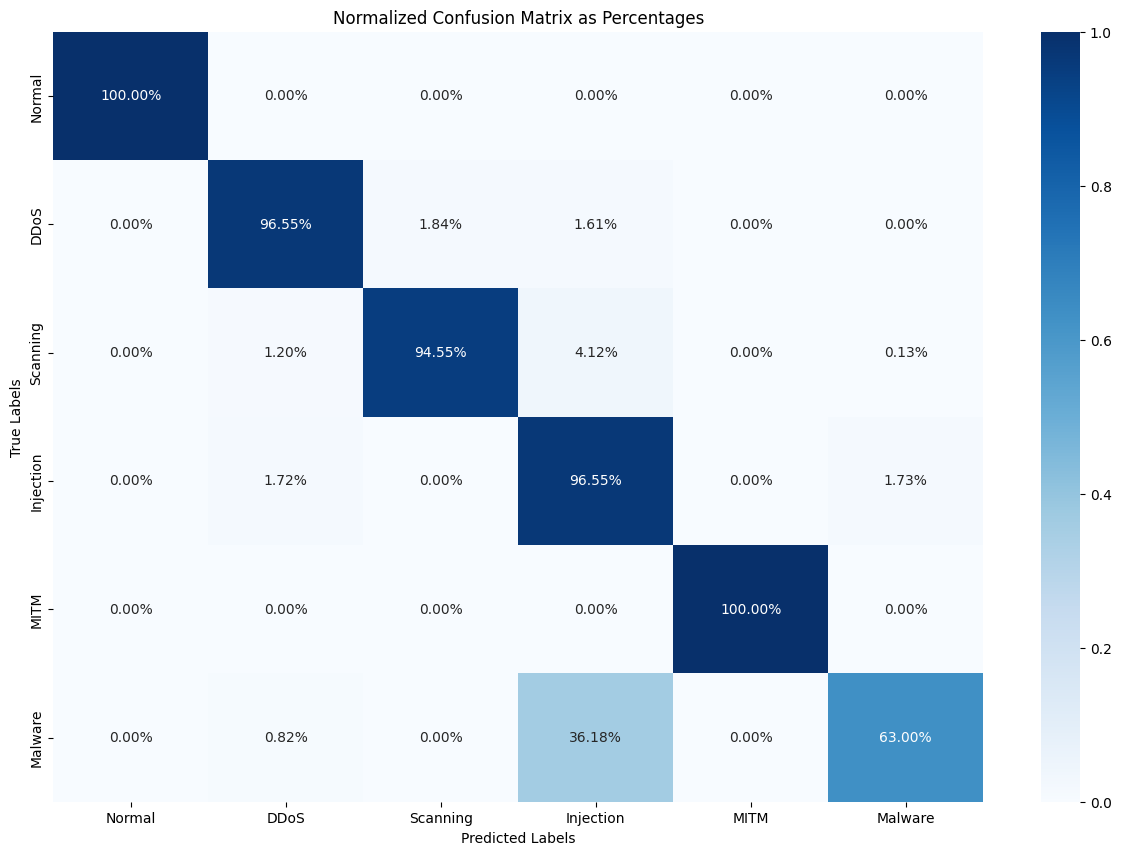

In [26]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')